# KGCV-Strawberry: knowledge-guided strawberry growth modeling — single-fruit demo (paper Fig. 17)

**Paper:** Qi Yang, Licheng Liu, Junxiong Zhou, Mary Rogers, Zhenong Jin (2024),
*Predicting the growth trajectory and yield of greenhouse strawberries based on knowledge-guided computer vision*,
**Computers and Electronics in Agriculture** 220:108911. [DOI 10.1016/j.compag.2024.108911](https://doi.org/10.1016/j.compag.2024.108911)

**Author code:** {repo} @ commit `{commit}` (MIT license, file `LICENSE` in the repository).
This notebook imports the authors' `KGCV_util.py` **unmodified** at that pinned commit and ports the demo
script `KGCV_Strawberry_demo.py` ("Demo of the KGCV-Strawberry framework, figure 17") into readable cells.

**Data / pretrained models:** Zenodo record [{rec}](https://doi.org/10.5281/zenodo.10957909)
(tagged-fruit images + LabelMe labels, daily weather and tagged-fruit measurement CSVs, six trained model files).

**Scope (one example, not a benchmark):** one tagged strawberry fruit (No. 12, 2023 season, six observations
07/26–08/11). For each observation: Faster R-CNN fruit detection aligned with the LabelMe label → densenet121
trait estimation (diameter / length / phenology) → knowledge-guided logistic curve fitting (parameter-Net) →
growth-Net final-size prediction → harvest-time estimate → fresh-weight estimate `0.51·V + 1.07 g` compared with
the observed 7.28 g. **Out of scope:** detector/CNN/MLP retraining, season-wide assimilation, and the
process-based model comparison of the paper.

**Execution status:** this notebook is a faithful, adapted execution of the author demo. Documented adaptations
(compatibility shims, font fallback, one guarded IndexError) are marked at the cell where they appear.
**AI-assisted adaptation notice / AI支援のお知らせ:** notebook cells were adapted from the authors' Python demo
script for Colab; the authors did not provide this Colab notebook. The executed example and listed checks were
validated, but untested behavior is not guaranteed.

**日本語の概要:** このノートブックは、著者公開コード(コミット `{commit}`)のデモスクリプト
(`KGCV_Strawberry_demo.py`、論文 Fig. 17)を 1 個体の標記果実(No. 12、2023 年、6 回計測)で実行します。
Faster R-CNN による果実検出 → densenet121 によるサイズ・フェノロジー推定 → 知識ガイド付き
ロジスティック曲線あてはめ(parameter-Net)→ growth-Net による最終サイズ予測 → 収穫までの日数推定 →
生重量推定(観測値 7.28 g との比較)という流れです。検出器・CNN・MLP の再学習、シーズン全体の
アシミレーション、プロセスベースモデルとの比較は範囲外です。

## Runtime selection / ランタイム選択

**Recommended: CPU** (`Runtime → Change runtime type → CPU`). The demo runs six ~1000×750 images through
Faster R-CNN (scaled to 1/4) and six 256×256 crops through densenet121 — seconds of compute. A **T4 GPU**
runtime is also supported: the author's own device selection `"cuda" if torch.cuda.is_available() else "cpu"`
(`KGCV_util.py` line 36) is preserved, and results are identical up to numerical noise.
The notebook downloads ~2.6 GB from Zenodo (2.4 GB tagged-image archive + 0.18 GB models) plus small CSVs,
and takes roughly 10–20 minutes end to end, dominated by download and extraction.

**Run all:** `Runtime → Run all`. **推奨ランタイムは CPU です**(T4 GPU でも同じ結果が得られます)。
Zenodo から約 2.6 GB をダウンロードするため、全体で 10〜20 分程度かかります。

In [ ]:
import sys, torch, torchvision
print("Python:", sys.version.split()[0])
print("torch:", torch.__version__, "| torchvision:", torchvision.__version__)
device = "cuda" if torch.cuda.is_available() else "cpu"   # author's own selection (KGCV_util.py:36)
print("device:", device)
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Python: 3.13.18
torch: 2.11.0+cpu | torchvision: 0.26.0+cpu
device: cpu


## Working directory / 作業ディレクトリ

The author demo uses repository-relative paths (`datasets/...`, `models/...`, `results/...`). We recreate that
layout under `/content/KGCV_Strawberry` so the author code runs unmodified. / 論文コードと同じ相対パス構成を
Colab 上に再現します。

In [ ]:
import os
WORK = "/content/KGCV_Strawberry"
os.makedirs(WORK, exist_ok=True)
os.chdir(WORK)
for sub in ["datasets/measurements", "models", "results"]:
    os.makedirs(sub, exist_ok=True)
print("working directory:", os.getcwd())

working directory: /content/KGCV_Strawberry


## Get the author's analysis library / 著者コードの取得

`KGCV_util.py` contains the model definitions (`NN_para` 70→128→64→32→3 MLP with input BatchNorm,
`NN_growth` 5→32→32→16→1 MLP, `ImageClassificationModel` densenet121 with a 3-output linear head), the
data-driven knowledge components (`getTrajectories`, `fitBoundary`, `retrieveHighQualityTraj`), the S-curve
`func`/`func_reverse`, and `calHavestTime_continuous`. We download this single file at the pinned commit and
verify its SHA-256 against the copy inspected on the authoring host, instead of pasting 1,300 lines into the
notebook. / 著者の `KGCV_util.py` を pinned コミットからダウンロードし、SHA-256 で検証してインポートします。

In [ ]:
import hashlib, urllib.request

COMMIT = "62bb6978fa7e0823d343094be705ef2110fdd66a"
KGCV_UTIL_SHA256 = "6af571afbd447c47b152c0260cb4c2dfc220f7cc270580381e9ae844427901c7"
url = "https://raw.githubusercontent.com/DigitalAgUMN/KGCV_Strawberry/%s/KGCV_util.py" % COMMIT
urllib.request.urlretrieve(url, "KGCV_util.py")
with open("KGCV_util.py", "rb") as f:
    data = f.read()
sha = hashlib.sha256(data).hexdigest()
assert sha == KGCV_UTIL_SHA256, "KGCV_util.py hash mismatch: %s" % sha
print("KGCV_util.py verified: %d bytes, sha256 OK" % len(data))

KGCV_util.py verified: 52835 bytes, sha256 OK


The download is verified byte-for-byte (SHA-256 against the copy inspected on the authoring host, itself
fetched by the trusted code-only helper from the pinned commit). We then import it as module `util`. Because
the author files set `font.family='Times New Roman'`, which Colab does not ship, we set a fallback font list
first (a documented, cosmetic-only adaptation). / ダウンロードした `KGCV_util.py` の SHA-256 を検証してから
インポートします。フォントは Colab にない Times New Roman の代替を設定します(見た目のみの変更)。

In [ ]:
import matplotlib
# Author files set font.family='Times New Roman', which is not installed on Colab.
# A fallback list keeps the author settings but avoids findfont warnings. (documented adaptation)
matplotlib.rcParams["font.family"] = ["Times New Roman", "DejaVu Sans"]
import KGCV_util as util
print("KGCV_util imported; torch device seen by the module:", "cuda" if torch.cuda.is_available() else "cpu")

cpu is available.
KGCV_util imported; torch device seen by the module: cpu


## Compatibility shims (AI-generated, documented) / 互換性シム

Two version adaptations, both preserving the author's configuration:

1. `KGCV_util.py` line 1079 instantiates `models.densenet121(pretrained=True)`. The `pretrained` argument was
   removed in torchvision ≥ 0.15, so we install a shim that drops the deprecated argument (no ImageNet weights
   are downloaded or used — the author's own checkpoint `densenet121_state_dict.pth` is loaded immediately after).
2. `models/fasterRcnn.pth` is a full-pickle model file (`torch.save(model)`, see
   `KGCV_Strawberry_Train_FasterRCNN.py:392`). PyTorch ≥ 2.6 defaults `weights_only=True`, which rejects such
   pickles; we load it explicitly with `weights_only=False`. The file comes from the authors' own Zenodo record
   with a verified MD5. / 著者コードが新しい torchvision / PyTorch で動くように、最小限の互換シムを入れます。

In [ ]:
import torchvision.models as _tvm
_orig_densenet121 = _tvm.densenet121
def _densenet121_compat(*args, **kwargs):
    kwargs.pop("pretrained", None)
    kwargs.setdefault("weights", None)
    return _orig_densenet121(*args, **kwargs)
_tvm.densenet121 = _densenet121_compat
print("Shim installed: densenet121 ignores the deprecated 'pretrained' argument (weights=None).")

Shim installed: densenet121 ignores the deprecated 'pretrained' argument (weights=None).


## Acquire data and models (Colab-only) / データ・モデルの取得

Everything below downloads into the Colab VM. From the Zenodo record **10957909** we need only two archives
(metadata inspected first from the record API):

- `strawberry_img_tagged.zip` — 2,377,705,505 bytes, md5 `942b2d3da247e7e8bff695a970ccdec0`. The **full**
  archive is required: the knowledge components (`getTrajectories`, `loadPhenoData`, `calHavestTime_continuous`)
  are computed from the complete 2022+2023 tagged-label corpus, so a selective subset would silently change the
  statistics. This is the disclosed heavy download (~2.4 GB).
- `models.zip` — 180,630,329 bytes, md5 `86acd650c7a3dce6eedadca7ddec5eaf` (six `.pth` files).

The small measurement CSVs come from the pinned GitHub commit instead (they are the author's in-repo copies).
`strawberry_img_random.zip` (4.3 GB, detector training images) is **not** needed for this demo.
/ このデモに必要な Zenodo アーカイブ 2 つと、GitHub pinned コミットの計測 CSV を Colab 内にダウンロードします。

In [ ]:
import json, urllib.request
REC_URL = "https://zenodo.org/api/records/10957909"
with urllib.request.urlopen(REC_URL, timeout=120) as r:
    record = json.load(r)
files = {f["key"]: f for f in record["files"]}
for key, f in sorted(files.items()):
    print("%-32s %12d bytes  %s" % (key, f["size"], f["checksum"]))
WANTED = ["strawberry_img_tagged.zip", "models.zip"]
for key in WANTED:
    assert key in files, key
print("record DOI:", record["metadata"].get("doi"), "| title:", str(record["metadata"].get("title"))[:70])

datasetProcessing.py                     2715 bytes  md5:17a4680326e2d075b3a1c8cf7dfd32a6
measurements.zip                        29449 bytes  md5:56e949f121a9a56a099f9bb3d892e797
models.zip                          180630329 bytes  md5:86acd650c7a3dce6eedadca7ddec5eaf
strawberry_img_random.zip          4267749039 bytes  md5:56a49daa5df9fa7b65a807c102db0ca7
strawberry_img_tagged.zip          2377705505 bytes  md5:942b2d3da247e7e8bff695a970ccdec0
record DOI: 10.5281/zenodo.10957909 | title: Dataset for "Predicting the growth trajectory and yield of greenhouse 


### Download `models.zip` (180 MB) / models.zip のダウンロード

Streamed from the record's returned content URL with per-chunk MD5 computation; size and MD5 are asserted
against the record metadata printed above. / Zenodo の返したコンテント URL からストリーミングダウンロードし、
サイズと MD5 を検証します。

In [ ]:
import time
import hashlib, requests

def zenodo_download(key, expected_md5, expected_size):
    url = "https://zenodo.org/api/records/10957909/files/%s/content" % key
    t0 = time.time()
    with requests.get(url, stream=True, timeout=300) as r:
        r.raise_for_status()
        print(key, "HTTP", r.status_code, r.headers.get("Content-Type"), "->", r.headers.get("Content-Length"))
        h = hashlib.md5()
        n = 0
        with open(key, "wb") as f:
            for chunk in r.iter_content(chunk_size=1 << 22):
                f.write(chunk)
                h.update(chunk)
                n += len(chunk)
                if n % (200 << 20) < (1 << 22):
                    print("  %s: %.2f GB" % (key, n / 1e9), flush=True)
    got = h.hexdigest()
    assert n == expected_size, "size mismatch for %s: %d" % (key, n)
    assert got == expected_md5, "md5 mismatch for %s: %s" % (key, got)
    print("%s verified: %d bytes, md5 %s OK (%.0f s)" % (key, n, got, time.time() - t0))

zenodo_download("models.zip", "86acd650c7a3dce6eedadca7ddec5eaf", 180630329)

models.zip HTTP 200 application/octet-stream, application/octet-stream -> 180630329


models.zip verified: 180630329 bytes, md5 86acd650c7a3dce6eedadca7ddec5eaf OK (59 s)


### Download `strawberry_img_tagged.zip` (2.4 GB) / tagged アーカイブのダウンロード

The heavy, disclosed download. Same verification as above; progress is printed every ~200 MB.
This is the only step that justifies most of the runtime — it contains the complete tagged-label corpus the
knowledge components are computed from. / ここが最重量のダウンロードです(約 2.4 GB)。知識成分の計算に
必要な全ラベルコーパスを含みます。

In [ ]:
zenodo_download("strawberry_img_tagged.zip", "942b2d3da247e7e8bff695a970ccdec0", 2377705505)

strawberry_img_tagged.zip HTTP 200 application/octet-stream, application/octet-stream -> 2377705505


  strawberry_img_tagged.zip: 0.21 GB


  strawberry_img_tagged.zip: 0.42 GB


  strawberry_img_tagged.zip: 0.63 GB


  strawberry_img_tagged.zip: 0.84 GB


  strawberry_img_tagged.zip: 1.05 GB


... (3 outputs left out)

  strawberry_img_tagged.zip: 1.89 GB


  strawberry_img_tagged.zip: 2.10 GB


  strawberry_img_tagged.zip: 2.31 GB


strawberry_img_tagged.zip verified: 2377705505 bytes, md5 942b2d3da247e7e8bff695a970ccdec0 OK (408 s)


### Extract the archives / アーカイブの展開

Extract the six `.pth` model files into `models/` and the full tagged-image archive under
`datasets/strawberry_img_tagged/` (the directory name is normalized if the archive nests it differently).
We then assert the six demo files `YYYYMMDD_12.jpg/.json` exist. / モデル 6 ファイルと tagged 画像アーカイブを
展開し、デモに必要な 6 観測分のファイルがあることを確認します。

In [ ]:
import zipfile
with zipfile.ZipFile("models.zip") as z:
    print("models.zip entries:", z.namelist())
    z.extractall("models_extract")
import glob, shutil
pths = sorted(glob.glob("models_extract/**/*.pth", recursive=True))
assert len(pths) == 6, "expected 6 model files, found %d: %s" % (len(pths), pths)
for p in pths:
    shutil.copy(p, "models/" + os.path.basename(p))
print("models/:", sorted(os.listdir("models")))

models.zip entries: ['models/', 'models/densenet121_state_dict.pth', 'models/fasterRcnn.pth', 'models/growNet_state_dict_diameter.pth', 'models/growNet_state_dict_length.pth', 'models/paraNet_state_dict_diameter.pth', 'models/paraNet_state_dict_length.pth']


models/: ['densenet121_state_dict.pth', 'fasterRcnn.pth', 'growNet_state_dict_diameter.pth', 'growNet_state_dict_length.pth', 'paraNet_state_dict_diameter.pth', 'paraNet_state_dict_length.pth']


### Extract `strawberry_img_tagged.zip` / tagged アーカイブの展開

The full 2.4 GB archive is extracted so the knowledge components see the complete label corpus; the top-level
directory is normalized to `datasets/strawberry_img_tagged/`. / 2.4 GB のアーカイブを展開し、知識成分用の
完全なラベルコーパスを配置します。

In [ ]:
with zipfile.ZipFile("strawberry_img_tagged.zip") as z:
    names = z.namelist()
    print("entries:", len(names), "| top-level:", sorted({n.split("/")[0] for n in names})[:5])
    z.extractall("datasets")

import glob, shutil
tagdir = "datasets/strawberry_img_tagged"
if not os.path.isdir(tagdir):
    for d in sorted(glob.glob("datasets/*")):
        if os.path.isdir(d) and glob.glob(os.path.join(d, "2023*.jpg")):
            shutil.move(d, tagdir)
            break
assert os.path.isdir(tagdir), "tagged image directory not found; contents: %s" % sorted(glob.glob("datasets/*"))[:10]
n_jpg = len(glob.glob(tagdir + "/*.jpg"))
n_json = len(glob.glob(tagdir + "/*.json"))
print("tagged images:", n_jpg, "| label JSONs:", n_json)

entries: 1275 | top-level: ['strawberry_img_tagged']


tagged images: 637 | label JSONs: 637


The extracted archive must contain the complete 2022+2023 label corpus; we check the six demo observation
files explicitly. / 展開後、デモに必要な 6 観測分のファイルを明示的に確認します。

In [ ]:
demo_stems = ["20230726_12", "20230729_12", "20230801_12", "20230804_12", "20230807_12", "20230811_12"]
missing = [s for s in demo_stems
           if not (os.path.exists("datasets/strawberry_img_tagged/%s.jpg" % s)
                   and os.path.exists("datasets/strawberry_img_tagged/%s.json" % s))]
assert not missing, "missing demo files: %s" % missing
print("all six demo observations (fruit 12) present in the extracted archive")

all six demo observations (fruit 12) present in the extracted archive


## Measurement CSVs from the pinned commit / pinned コミットの計測 CSV

`getTrajectories` reads daily weather (2022/2023) and tagged-fruit diameter/length tables (2022/2023) from
`datasets/measurements/`. These six small CSVs exist in the author repository at the pinned commit; we download
them from raw.githubusercontent.com and verify each file's **git blob SHA-1** (recorded from the repository tree
API at commit `62bb6978`) so the bytes are pinned. / 6 つの CSV を GitHub の pinned コミットから取得し、
git blob SHA-1 で検証します。

In [ ]:
CSV_BLOBS = {
    "weather_daily_2022.csv": "0914ee4d70c19801ddec93eb6e92a48ca3028aed",
    "weather_daily_2023.csv": "43111c6f1802b9769875f058530b0d9a75ffa790",
    "data_taggedFruit_diameter_2022.csv": "3d0d26ec4d10aeba4011c5943ceac7c5dfac766e",
    "data_taggedFruit_diameter_2023.csv": "9c7a140e2584d4fef4edcc29119a659bf01800d7",
    "data_taggedFruit_length_2022.csv": "4bffcb7ba9b42f1278f501b5f7ad14e8ac3c00e4",
    "data_taggedFruit_length_2023.csv": "93c655958364335e0fb18a0426f267c44212e5d1",
}

def git_blob_sha1(path):
    with open(path, "rb") as f:
        data = f.read()
    h = hashlib.sha1()
    h.update(b"blob %d\0" % len(data))
    h.update(data)
    return h.hexdigest()

for name, blob_sha in CSV_BLOBS.items():
    dest = "datasets/measurements/" + name
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/DigitalAgUMN/KGCV_Strawberry/%s/datasets/measurements/%s" % (COMMIT, name),
        dest)
    got = git_blob_sha1(dest)
    assert got == blob_sha, "blob sha1 mismatch for %s: %s" % (name, got)
    print("%-38s blob sha1 OK  %s" % (name, got))

weather_daily_2022.csv                 blob sha1 OK  0914ee4d70c19801ddec93eb6e92a48ca3028aed
weather_daily_2023.csv                 blob sha1 OK  43111c6f1802b9769875f058530b0d9a75ffa790
data_taggedFruit_diameter_2022.csv     blob sha1 OK  3d0d26ec4d10aeba4011c5943ceac7c5dfac766e


data_taggedFruit_diameter_2023.csv     blob sha1 OK  9c7a140e2584d4fef4edcc29119a659bf01800d7
data_taggedFruit_length_2022.csv       blob sha1 OK  4bffcb7ba9b42f1278f501b5f7ad14e8ac3c00e4
data_taggedFruit_length_2023.csv       blob sha1 OK  93c655958364335e0fb18a0426f267c44212e5d1


## The demo fruit (ported from `KGCV_Strawberry_demo.py:246-256`) / デモ果実の定義

Tagged fruit **No. 12**, 2023 season, six manual observations 07/26–08/11 with observed diameter/length (mm),
accumulated GDD since the "small green" stage (computed by the authors from the greenhouse weather, Tbase=3 °C,
Tup=40 °C — see `GDDcal(Tbase=3, Tup=40)` in `getTrajectories`), and the observed harvest fresh weight 7.28 g.
The image paths follow the author's `datasets/strawberry_img_tagged/YYYYMMDD_12.jpg` convention.
/ デモ対象は No. 12 の標記果実。6 回の観測値(直径・長さ・GDD)と収穫時の生重量 7.28 g を著者デモの通り
定義します。

In [ ]:
import datetime, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image, ImageOps

class demoTrajectory():
    """Ported verbatim from KGCV_Strawberry_demo.py lines 246-256."""
    def __init__(self):
        ids = 12  # the No. on the tag of the demo fruit
        obs_dates = ["07/26/2023", "07/29/2023", "08/01/2023", "08/04/2023", "08/07/2023", "08/11/2023"]
        self.dates = [datetime.datetime.strptime(t, "%m/%d/%Y") for t in obs_dates]
        self.diameter = [8.05, 11.39, 11.42, 14.5, 18.45, 23.94]
        self.length = [10.09, 14.19, 15.72, 19.53, 25.3, 30.93]
        self.GDDlist = [0, 75.8755982300445, 141.46474267187557, 216.5649807375197, 283.1683296767341, 369.87646102173585]
        self.freshYield = "7.28"  # for No.12 Jul. 26 - Aug.11
        imgRoot = "datasets/strawberry_img_tagged"
        self.imgPathes = ["%s/%s_%s" % (imgRoot, t.strftime("%Y%m%d"), ids) for t in self.dates]
    def __len__(self):
        return len(self.dates)

demo = demoTrajectory()
print("observations:", len(demo), "| image example:", demo.imgPathes[0])
pd.DataFrame({"date": [d.strftime("%m/%d/%Y") for d in demo.dates],
              "obs diameter (mm)": demo.diameter,
              "obs length (mm)": demo.length,
              "GDD since small green": demo.GDDlist})

observations: 6 | image example: datasets/strawberry_img_tagged/20230726_12


,date,obs diameter (mm),obs length (mm),GDD since small green
0,07/26/2023,8.05,10.09,0.000000
1,07/29/2023,11.39,14.19,75.875598
2,08/01/2023,11.42,15.72,141.464743
3,08/04/2023,14.50,19.53,216.564981
4,08/07/2023,18.45,25.30,283.168330
5,08/11/2023,23.94,30.93,369.876461


## Input preview: the six demo observations / 入力プレビュー

Original greenhouse images of fruit No. 12 with their **LabelMe ground-truth fruit boxes (green)** from the
`YYYYMMDD_12.json` label files — the same labels the detection below is aligned against. These are the actual
inputs required by the reproduction (extracted above from `strawberry_img_tagged.zip`).
/ デモに使う 6 枚の温室画像と、LabelMe アノテーション(緑の正解ボックス)を表示します。

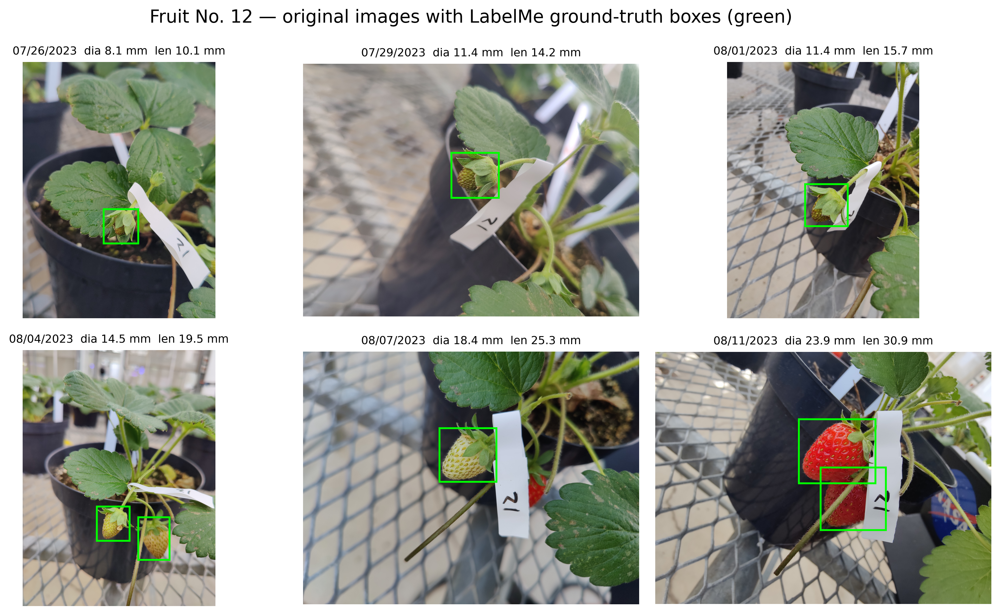

In [ ]:
fig, axs = plt.subplots(2, 3, figsize=(12, 7))
for ax, stem in zip(axs.flat, demo_stems):
    im = ImageOps.exif_transpose(Image.open("datasets/strawberry_img_tagged/%s.jpg" % stem).convert("RGB"))
    ax.imshow(im)
    with open("datasets/strawberry_img_tagged/%s.json" % stem) as f:
        lab = json.load(f)
    for sh in lab["shapes"]:
        xs = [p[0] for p in sh["points"]]
        ys = [p[1] for p in sh["points"]]
        ax.add_patch(patches.Rectangle((min(xs), min(ys)), max(xs) - min(xs), max(ys) - min(ys),
                                       linewidth=1.5, edgecolor="lime", facecolor="none"))
    k = demo_stems.index(stem)
    ax.set_title("%s  dia %.1f mm  len %.1f mm" % (demo.dates[k].strftime("%m/%d/%Y"),
                                                   demo.diameter[k], demo.length[k]), fontsize=9)
    ax.axis("off")
plt.suptitle("Fruit No. 12 — original images with LabelMe ground-truth boxes (green)")
plt.tight_layout()
plt.show()

## Knowledge components from the tagged-fruit corpus / 知識コンポーネントの計算

The "knowledge-guided" part of KGCV: from the complete 2022+2023 corpus (weather CSVs + tagged-fruit size
tables + LabelMe phenology labels), the authors compute (a) a fitted S-shaped growth **boundary** function
`popt` (`fitBoundary(mode='diameter', per='mannul')`, manual boundaries `popt_up=[32,140,-0.017]`,
`popt_d=[21,410,-0.009]`), and (b) the **mean lifespan** of fully-observed trajectories (2023), used to convert
the estimated phenological stage into remaining growing-degree-days. This takes about a minute and prints the
authors' per-stage GDD statistics. Two grey trajectory-overview figures are produced by the author's
`plot_trajectary_pheno` inside `retrieveHighQualityTraj`. / 全計測コーパスから知識成分(成長境界曲線と平均寿命)
を著者コードのまま計算します。

mean small g GDD is 79.13900198131087
25.992807158767857 266.2467982911023 -0.00771130967948336
[np.float64(85.30222953839525), np.float64(130.4890768706464), np.float64(61.706589963070655), np.float64(83.69180236559234)]


[np.float64(138.07925992207964), np.float64(130.68642836408338), np.float64(97.02876776662373), np.float64(92.27672621772732)]


fitted boundary popt (y0, t0, r): [ 2.59928072e+01  2.66246798e+02 -7.71130968e-03]
manual boundaries: up [32, 140, -0.017] / down [21, 410, -0.009]
meanlifespan (2023, GDD+80): 490.6


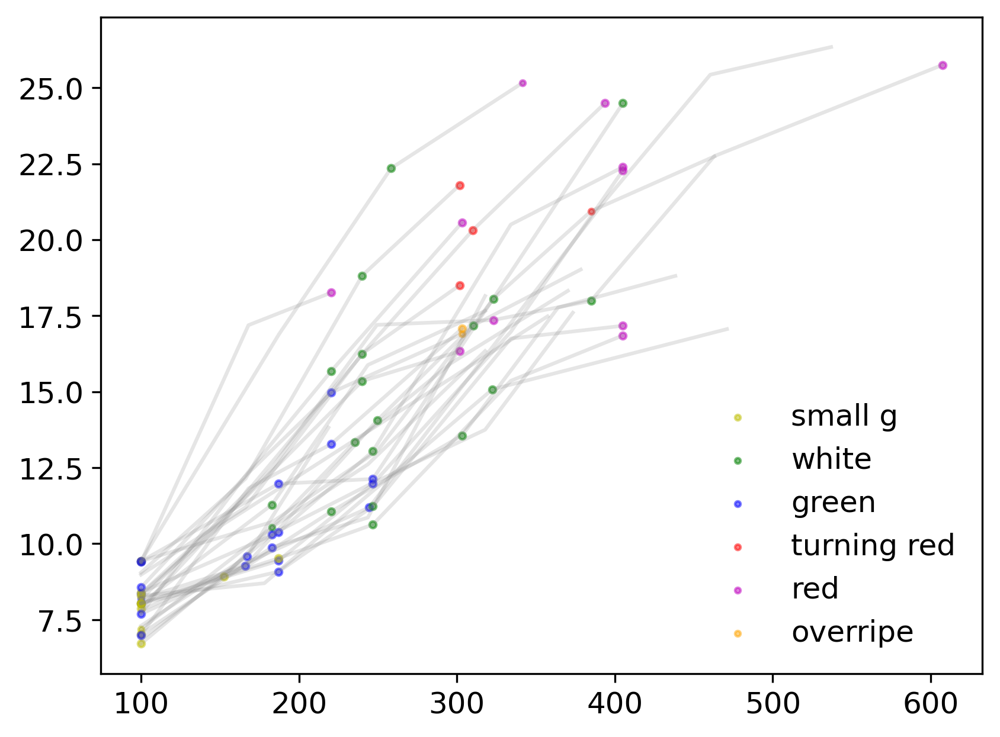

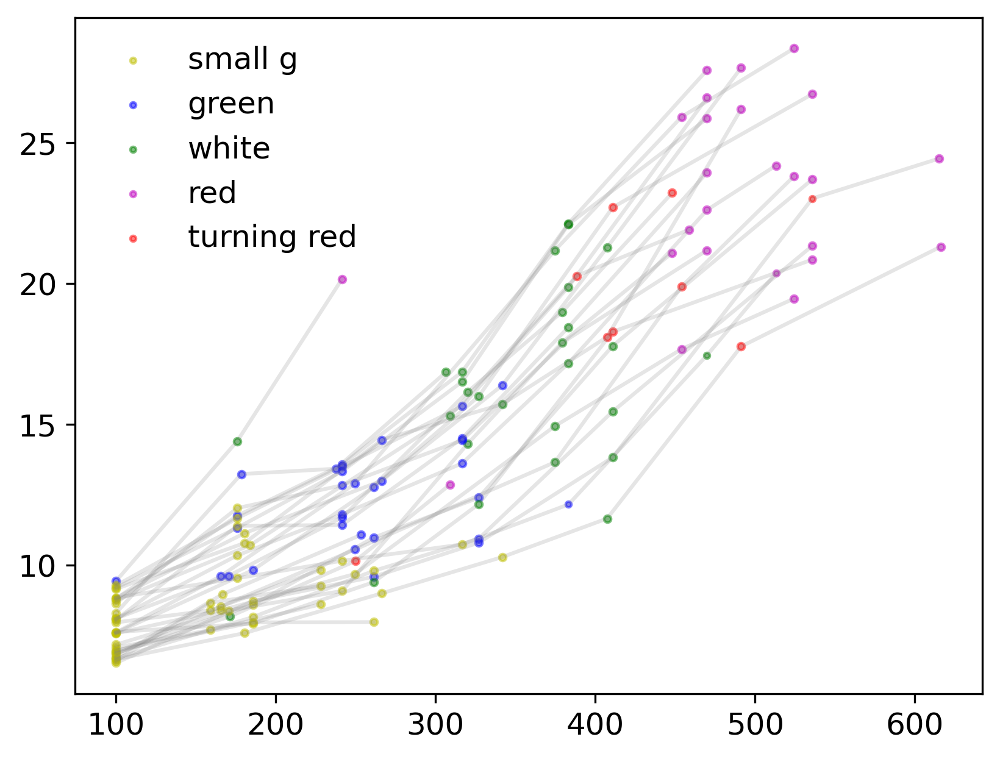

In [ ]:
traj = util.getTrajectories()
popt, popt_up, popt_d, aux, fig_b = traj.fitBoundary(mode="diameter", per="mannul", plot=False)
valid_traj_list, complete_traj_list, meanlifespan_list = traj.retrieveHighQualityTraj()
print("fitted boundary popt (y0, t0, r):", popt)
print("manual boundaries: up %s / down %s" % (popt_up, popt_d))
meanlifespan = meanlifespan_list[-1]   # 2023 season, as in the author demo
print("meanlifespan (2023, GDD+80): %.1f" % meanlifespan)

## Load the six pretrained models / 学習済みモデルの読み込み

All six weights come from the authors' Zenodo `models.zip` (MD5-verified above). We summarize each model's
structure without printing weight values: Faster R-CNN (`fasterrcnn_resnet50_fpn`, 8 classes: background,
flower, small g, green, white, turning red, red, overripe — `KGCV_Strawberry_Train_FasterRCNN.py:225-232`),
densenet121 trait CNN (3 outputs), two parameter-Nets (70→3), two growth-Nets (5→1).
The known author quirk at `KGCV_Strawberry_demo.py:295` — the **length** growth-Net is loaded from
`growNet_state_dict_diameter.pth` — is preserved exactly as in the author demo.
/ 6 つの学習済みモデルを読み込み、構造の要約を表示します(著者デモの length 用重みに diameter の重みを
使う行は著者コードのまま保持します)。

In [ ]:
model_fasterRcnn = torch.load("models/fasterRcnn.pth", map_location="cpu", weights_only=False)  # full-pickle model (author KGCV_Strawberry_demo.py:265)
model_fasterRcnn.to(device).eval()
print("Faster R-CNN classes:", model_fasterRcnn.roi_heads.box_predictor.cls_score.out_features)

model_cnn = util.ImageClassificationModel(model="densenet121", outNum=3)  # shim: no ImageNet download
model_cnn.load_state_dict(torch.load("models/densenet121_state_dict.pth", map_location="cpu"))  # author's own checkpoint
model_cnn.to(device).eval()
print("densenet121 head:", model_cnn.network.classifier)

model_para_dia = util.NN_para(input_dim=70, output_dim=3)
model_para_dia.load_state_dict(torch.load("models/paraNet_state_dict_diameter.pth", map_location="cpu"))
model_para_dia.to(device).eval()
model_para_len = util.NN_para(input_dim=70, output_dim=3)
model_para_len.load_state_dict(torch.load("models/paraNet_state_dict_length.pth", map_location="cpu"))
model_para_len.to(device).eval()
print("NN_para(dia) fc_1:", model_para_dia.fc_1.weight.shape, "| fc_4:", model_para_dia.fc_4.weight.shape)

model_grow_dia = util.NN_growth(input_dim=5, output_dim=1)
model_grow_dia.load_state_dict(torch.load("models/growNet_state_dict_diameter.pth", map_location="cpu"))
model_grow_dia.to(device).eval()
model_grow_len = util.NN_growth(input_dim=5, output_dim=1)
model_grow_len.load_state_dict(torch.load("models/growNet_state_dict_diameter.pth", map_location="cpu"))  # author demo line 295 (kept as-is)
model_grow_len.to(device).eval()
print("NN_growth fc_1:", model_grow_dia.fc_1.weight.shape, "| fc_4:", model_grow_dia.fc_4.weight.shape)
print("all six models loaded")

Faster R-CNN classes: 8


densenet121 head: Linear(in_features=1024, out_features=3, bias=True)
NN_para(dia) fc_1: torch.Size([128, 70]) | fc_4: torch.Size([3, 32])
NN_growth fc_1: torch.Size([32, 5]) | fc_4: torch.Size([1, 16])
all six models loaded


## Detection-alignment helpers (ported from `KGCV_Strawberry_demo.py:33-58, 93-131, 196-221`) / 検出ヘルパー

`cal_IoU` computes box overlap; `showRes(..., plot=False)` aligns **predicted** boxes to the LabelMe
ground-truth boxes by IoU > 0.4, keeping the highest-scored prediction per ground-truth box;
`cropImgByBbox` crops a 30 %-enlarged square around each aligned box and resizes to 256×256 for the trait CNN.
Ported with the author's original logic and thresholds. / 著者コードから、IoU による検出ボックスの
アラインメントと 256×256 クロップのヘルパーを移植します。

In [ ]:
def cal_IoU(rec1, rec2):
    """(x0, y0, x1, y1) IoU — ported verbatim from KGCV_Strawberry_demo.py:33."""
    S_rec1 = (rec1[2] - rec1[0]) * (rec1[3] - rec1[1])
    S_rec2 = (rec2[2] - rec2[0]) * (rec2[3] - rec2[1])
    sum_area = S_rec1 + S_rec2
    left_line = max(rec1[0], rec2[0]); right_line = min(rec1[2], rec2[2])
    top_line = max(rec1[1], rec2[1]); bottom_line = min(rec1[3], rec2[3])
    if left_line >= right_line or top_line >= bottom_line:
        return 0
    intersect = (right_line - left_line) * (bottom_line - top_line)
    return (intersect / (sum_area - intersect)) * 1.0

def showRes(img_t, bboxes, bboxes_p, labels_p, score_p, score_thresh=0.5, IoU_treshold=0.4, plot=True):
    """Align predictions to ground-truth boxes by IoU — logic of KGCV_Strawberry_demo.py:93-131 (plot branch omitted)."""
    bboxes_p_aligned, labels_p_aligned, score_p_aligned = [], [], []
    for box_true in bboxes:
        IoU_t = [cal_IoU(box_true, box_p) for box_p in bboxes_p]
        validindex = np.array(IoU_t) > IoU_treshold
        scores = np.array(score_p)[validindex]
        if len(scores) > 0:
            maxindex = score_p.index(np.max(scores))
            if IoU_t[maxindex] > IoU_treshold:
                bboxes_p_aligned.append(bboxes_p[maxindex])
                labels_p_aligned.append(labels_p[maxindex])
                score_p_aligned.append(score_p[maxindex])
    return _, bboxes_p_aligned, labels_p_aligned

def cropImgByBbox(img, bboxes, obj_enlarge=0.3, obj_size=256, transforms=None):
    """Crop 30%-enlarged squares and resize to 256x256 — ported verbatim from KGCV_Strawberry_demo.py:196."""
    img_obj_list = []
    for boxes in bboxes:
        xmin, xmax, ymin, ymax = boxes[0], boxes[2], boxes[1], boxes[3]
        obj_width, obj_height = xmax - xmin, ymax - ymin
        maxEdge = int(np.max([obj_width, obj_height]))
        cetral = (int((xmin + xmax) / 2), int((ymin + ymax) / 2))
        img_obj = img.crop(((cetral[0] - (1 + obj_enlarge) * maxEdge / 2),
                            (cetral[1] - (1 + obj_enlarge) * maxEdge / 2),
                            (cetral[0] + (1 + obj_enlarge) * maxEdge / 2),
                            (cetral[1] + (1 + obj_enlarge) * maxEdge / 2)))
        img_obj = img_obj.resize((obj_size, obj_size), resample=Image.Resampling.BILINEAR)
        if transforms is not None:
            img_obj, _ = transforms(img_obj)
        img_obj_list.append(img_obj)
    return img_obj_list

trans = util.ToTensor()
scale = 1/4              # author demo line 304
normlize_coef = 1/40     # author demo line 303
validlabel = ["background", "flower", "small g", "green", "white", "turning red", "red", "overripe"]  # author line 305
print("detection helpers ready (scale=%s, normlize_coef=%s)" % (scale, normlize_coef))

detection helpers ready (scale=0.25, normlize_coef=0.025)


## Estimation helpers (ported from `KGCV_Strawberry_demo.py:133-194, 223-244`) / 推定ヘルパー

`paraEstimation` embeds the sparse observed sequence into a 1×70 vector (10-GDD resolution, values scaled by
1/50) and runs the pretrained parameter-Net to get the three S-curve parameters `(y0, t0, r)`; it also saves
the fitted curve plot, as in the author demo (the author's global loop-variable filename is replaced by an
explicit `number` argument — same filenames, no semantic change). `showRes_size_ax` draws one panel with the
predicted box, estimated/observed sizes, remaining days, final-size predictions, and the fresh-weight formula
`0.51·V + 1.07 g` (paper Eq. for fresh weight; demo lines 148-150, 177-179). / スパースな観測系列から
parameter-Net で S 字曲線パラメータを推定し、結果パネルを描画するヘルパーです。

In [ ]:
def paraEstimation(x_s, y_s, model_para, plot=True, ylabel="", number=""):
    """Parameter-Net inference on a sparse size sequence — ported from KGCV_Strawberry_demo.py:223-244."""
    xscale = 1/50
    resolution = 10
    para_scale = np.array([1/50, 1/500, -50])
    x0_list = np.arange(0, 700, resolution).astype(np.float32)
    x_index = np.round((np.array(x_s)) / resolution).astype(np.int64)
    tmp = np.zeros(len(x0_list))
    tmp[x_index] = np.array(y_s) * xscale
    para_in = torch.unsqueeze(torch.tensor(tmp.astype(np.float32)).to(device), dim=0)
    model_para.eval()
    cali_p = torch.squeeze(model_para(para_in)).detach().cpu().numpy() / para_scale
    if plot:
        fig, ax = plt.subplots(1, 1)
        t = np.linspace(0, 600)
        ax.plot(t, util.func(t, *cali_p), "r-", label="Fitted Logistic curve")
        ax.scatter(np.array(x_s), np.array(y_s))
        ax.set_xlabel("GDD")
        ax.set_ylabel(ylabel)
        fig.savefig("results/curve_fitting_%s_%s.png" % (ylabel, number), bbox_inches="tight")
        plt.close(fig)
    return cali_p

def showRes_size_ax(ax, img_t, bbox, dia, length, dia_obs=None, len_obs=None, harvestEst=None,
                    harvestObs=None, final_dia=None, final_len=None, final_yield=None):
    """One result panel — ported from KGCV_Strawberry_demo.py:162-194."""
    img = img_t.cpu().numpy().transpose(1, 2, 0)
    if img.shape[0] > img.shape[1]:
        img = img.transpose(1, 0, 2)
        bbox = [bbox[1], bbox[0], bbox[3], bbox[2]]
    ax.imshow(img)
    w = bbox[2] - bbox[0]
    h = bbox[3] - bbox[1]
    rect = patches.Rectangle((bbox[0], bbox[1]), w, h, linewidth=1, edgecolor="r", facecolor="none")
    ax.add_patch(rect)
    r = dia / 2
    v = np.pi * (r**2) * length / 1000  # cm^3
    freshweight = 0.51 * v + 1.07  # g  (paper fresh-weight formula, demo lines 148-150)
    ax.text(bbox[0] - 2, bbox[1],
            "Est. diameter: %.1f mm\nEst. length: %.1f mm\nEst. fresh weight: %.1f g\nEst. remaining days: %s\nPred. final D %s\nPred. final L %s" % (dia, length, freshweight, harvestEst, final_dia, final_len),
            bbox=dict(facecolor="r", edgecolor=(0, 0, 0, 0), pad=0), color="w", fontsize=7)
    if final_yield is None:
        ax.text(bbox[0] - 2, bbox[3] + 1,
                "Obs. diameter: %s mm\nObs. length: %s mm\nObs. remaining days: %s" % (dia_obs, len_obs, harvestObs),
                bbox=dict(facecolor="g", edgecolor=(0, 0, 0, 0), pad=0), color="w", fontsize=7,
                horizontalalignment="left", verticalalignment="top")
    else:
        ax.text(bbox[0] - 2, bbox[3] + 1,
                "Obs. diameter: %s mm\nObs. length: %s mm\nObs. remaining days: %s\nObs. fresh weight: %s g" % (dia_obs, len_obs, harvestObs, final_yield),
                bbox=dict(facecolor="g", edgecolor=(0, 0, 0, 0), pad=0), color="w", fontsize=7,
                horizontalalignment="left", verticalalignment="top")
    ax.axis("off")

print("estimation helpers ready")

estimation helpers ready


## Run the KGCV demo loop (paper Fig. 17) / KGCV デモ本体の実行

For each of the six observations, exactly the author demo's steps
(`KGCV_Strawberry_demo.py:321-429`): open image → EXIF transpose → resize ×1/4 → read LabelMe boxes →
Faster R-CNN inference → IoU-align to ground truth → crop 256×256 → densenet121 traits (diameter, length,
phenology, normalized by 1/40 and 0.1 as in the demo) → update the accumulated GDD (first observation inverted
through the boundary curve via `func_reverse`; later observations offset by the author's `GDDlist`) →
parameter-Net curve fitting → harvest-time estimate (`calHavestTime_continuous` with the 2023 meanlifespan) →
growth-Net final size (kept ≥ current estimate). The known author guard at demo lines 381-382 would raise
`IndexError` when no detection aligns; here an explicit warning is printed and the panel is skipped
(**documented adaptation**). / 著者デモの各ステップを 6 観測分そのまま実行します。検出がアラインしなかった
場合の IndexError は、明示的な警告に置き換えています(文書化済みの変更)。

In [ ]:
currentGDDList = []   # GDD from the small-green stage (author demo line 314)
diaList, lengthList, phenofList = [], [], []
numList = ["(a)", "(b)", "(c)", "(d)", "(e)", "(f)"]

def run_demo_observation(i, ax):
    """One observation = KGCV_Strawberry_demo.py:323-429, ported with the documented guard."""
    img = Image.open("%s.jpg" % demo.imgPathes[i]).convert("RGB")
    size_0 = img.size
    img = ImageOps.exif_transpose(img)  # author line 325
    if size_0 != img.size:
        print("img %s transposed by EXIF: %s -> %s" % (demo.imgPathes[i], size_0, img.size))
    img = img.resize((int(img.size[0] * scale), int(img.size[1] * scale)), resample=0)
    img_t, _ = trans(img)

    with open("%s.json" % demo.imgPathes[i], "r") as f:  # ground-truth label boxes
        labeldata = json.load(f)
    bboxes = []
    for label in labeldata["shapes"]:
        xmin = label["points"][0][0] * scale
        xmax = label["points"][1][0] * scale
        ymin = label["points"][0][1] * scale
        ymax = label["points"][1][1] * scale
        bboxes.append([xmin, ymin, xmax, ymax])

    predicted = model_fasterRcnn(img_t.unsqueeze(0).to(device))
    bboxes_p = predicted[0]["boxes"].cpu().tolist()
    labels_p = predicted[0]["labels"].cpu().tolist()
    score_p = predicted[0]["scores"].cpu().tolist()

    _, bboxes_p_aligned, labels_p_aligned = showRes(img_t, bboxes, bboxes_p, labels_p, score_p, plot=False)
    img_obj_list = cropImgByBbox(img, bboxes_p_aligned, obj_enlarge=0.2, obj_size=256, transforms=trans)
    if len(img_obj_list) == 0:  # documented adaptation of demo lines 381-382 (author: IndexError)
        skipped = "obs %d (%s): no detection aligned with the label box (IoU>0.4); panel skipped." % (
            i, demo.dates[i].strftime("%m/%d/%Y"))
        print(skipped)
        return None

    t = img_obj_list[0]
    res_tmp = torch.squeeze(model_cnn(t.unsqueeze(0).to(device)))
    dia_p = (res_tmp[0] / normlize_coef).cpu().detach().numpy()
    len_p = (res_tmp[1] / normlize_coef).cpu().detach().numpy()
    phenof_p = (res_tmp[2] / 0.1).cpu().detach().numpy()
    dia_obs, len_obs = "%.1f" % demo.diameter[i], "%.1f" % demo.length[i]
    diaList.append(dia_p); lengthList.append(len_p); phenofList.append(phenof_p)

    timeSpan = [(demo.dates[i] - datetime.timedelta(7)).strftime("%m/%d/%Y"),
                demo.dates[i].strftime("%m/%d/%Y")]
    tmp = traj.weather.iloc[traj.weather[traj.weather["Date"] == timeSpan[0]].index[0]:
                            traj.weather[traj.weather["Date"] == timeSpan[1]].index[0]]
    mean_dailyGDD = np.mean(tmp["GDD"])

    if i == 0:  # invert the boundary S-curve to locate the first observation (author lines 385-387)
        currentGDD = max(util.func_reverse(dia_p, *popt), 0)
    else:
        currentGDD = currentGDDList[0] + demo.GDDlist[i]
    currentGDDList.append(currentGDD)

    cali_p_dia = paraEstimation(x_s=currentGDDList, y_s=diaList, model_para=model_para_dia,
                                ylabel="Diameter mm", number=i)
    cali_p_len = paraEstimation(x_s=currentGDDList, y_s=lengthList, model_para=model_para_len,
                                ylabel="Length mm", number=i)

    remainedGDD, remainedDay_f = util.calHavestTime_continuous(mean_dailyGDD, currentGDD, pheno=phenof_p,
                                                              plot=False, meanlifespan=meanlifespan)
    remainedDay = "%.1f days" % remainedDay_f
    remainedDayObs = "%s days" % (demo.dates[-1] - demo.dates[i]).days

    # final-size prediction with the growth-Nets (author lines 402-409)
    inTensor = torch.tensor(np.array([float(dia_p), remainedGDD, *cali_p_dia]).astype(np.float32)).to(device).unsqueeze(dim=0)
    final_dia = max(model_grow_dia(inTensor).item() / (1/50), float(dia_p))
    final_dia = "%.1f mm" % final_dia
    inTensor = torch.tensor(np.array([float(len_p), remainedGDD, *cali_p_len]).astype(np.float32)).to(device).unsqueeze(dim=0)
    final_len = max(model_grow_len(inTensor).item() / (1/50), float(len_p))
    final_len = "%.1f mm" % final_len

    showRes_size_ax(ax, img_t, bboxes_p_aligned[0], dia_p, len_p, dia_obs, len_obs,
                    harvestEst=remainedDay, harvestObs=remainedDayObs, final_dia=final_dia,
                    final_len=final_len, final_yield=(demo.freshYield if i == 5 else None))
    ax.text(50, 50, numList[i], fontsize=18, ha="center", va="center", color="black",
            bbox=dict(boxstyle="square", facecolor="white", edgecolor="none"))

    fw_est = 0.51 * (np.pi * (float(dia_p) / 2) ** 2 * float(len_p) / 1000) + 1.07
    return {"obs_date": demo.dates[i].strftime("%m/%d/%Y"),
            "GDD since small green": float(currentGDD),
            "est. diameter (mm)": float(dia_p), "est. length (mm)": float(len_p),
            "est. phenology (0-7)": float(phenof_p),
            "est. remaining days": float(remainedDay_f), "obs. remaining days": (demo.dates[-1] - demo.dates[i]).days,
            "pred. final diameter": final_dia, "pred. final length": final_len,
            "est. fresh weight (g)": fw_est}

print("demo loop function defined")

demo loop function defined


### Execute the demo over the six observations / 6 観測分のデモ実行

The 3×2 panel below is the notebook's counterpart of the author demo's `results/KGCV_demo.png` (paper
Fig. 17): each panel shows one observation image with the aligned predicted box (red), estimated and observed
sizes/remaining days, and — on the last panel — the observed fresh weight. Rows are collected for the results
table. / 著者デモの `results/KGCV_demo.png` 相当の 3×2 パネルを描画し、表用の行を収集します。

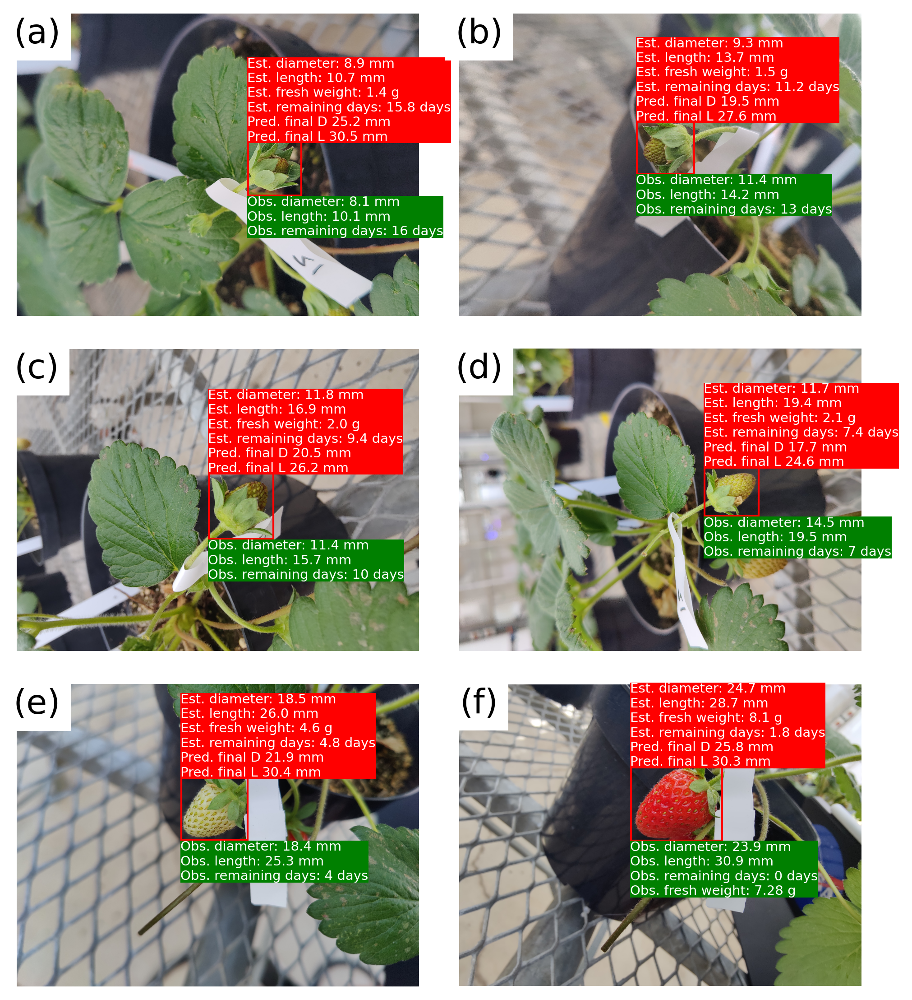

processed observations: 6 / 6


In [ ]:
fig, axs = plt.subplots(3, 2, figsize=(7.8, 9))
axx = axs.flatten(order="C")
rows = []
for i in range(len(demo)):
    row = run_demo_observation(i, axx[i])
    if row is not None:
        rows.append(row)
fig.subplots_adjust(left=0.1, right=0.9, top=0.9, bottom=0.1, wspace=0.1, hspace=0.1)
fig.savefig("results/KGCV_demo.png", bbox_inches="tight")
plt.show()
results_df = pd.DataFrame(rows)
print("processed observations: %d / 6" % len(rows))

## Results: fitted curves and per-observation table / 結果の表示

The overview panel (top) reproduces the author demo's `results/KGCV_demo.png`; the two panels next to it are
the last-observation curve fits saved by `paraEstimation` (GDD from the small-green stage on the x-axis).
The table lists the estimated values per observation, and the final cell compares the estimated fresh weight
on 08/11 with the observed 7.28 g. / デモの結果パネル、最終観測時の曲線あてはめ、観測ごとの推定値の表を
表示します。

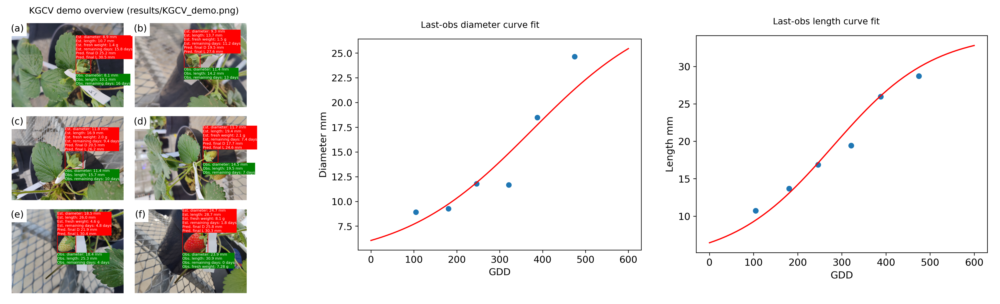

,obs_date,GDD since small green,est. diameter (mm),est. length (mm),est. phenology (0-7),est. remaining days,obs. remaining days,pred. final diameter,pred. final length,est. fresh weight (g)
0,07/26/2023,104.755275,8.915675,10.714684,1.491062,15.840856,16,25.2 mm,30.5 mm,1.411152
1,07/29/2023,180.630873,9.267497,13.672204,1.938808,11.224080,13,19.5 mm,27.6 mm,1.540353
2,08/01/2023,246.220018,11.778258,16.860886,2.335946,9.350923,10,20.5 mm,26.2 mm,2.006920
3,08/04/2023,321.320256,11.659362,19.425314,2.815289,7.432161,7,17.7 mm,24.6 mm,2.127737
4,08/07/2023,387.923605,18.474440,25.971195,3.591663,4.842986,4,21.9 mm,30.4 mm,4.620541
5,08/11/2023,474.631736,24.650778,28.708412,5.394280,1.824345,0,25.8 mm,30.3 mm,8.057639


In [ ]:
import matplotlib.image as mpimg
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].imshow(mpimg.imread("results/KGCV_demo.png"))
axes[0].set_title("KGCV demo overview (results/KGCV_demo.png)", fontsize=9)
axes[0].axis("off")
axes[1].imshow(mpimg.imread("results/curve_fitting_Diameter mm_5.png"))
axes[1].set_title("Last-obs diameter curve fit", fontsize=9)
axes[1].axis("off")
axes[2].imshow(mpimg.imread("results/curve_fitting_Length mm_5.png"))
axes[2].set_title("Last-obs length curve fit", fontsize=9)
axes[2].axis("off")
plt.tight_layout()
plt.show()
results_df

### Fresh-weight comparison and CSV export / 生重量の比較と CSV 出力

The last observation (08/11) carries the observed harvest fresh weight 7.28 g in the author demo. We print the
estimated fresh weight from the estimated D/L with the same paper formula, the growth-Net final-size
predictions, and export the per-observation table to `results/kgcv_demo_results.csv`.
/ 最終観測の推定生重量と観測値 7.28 g を比較し、表を CSV に出力します。

In [ ]:
results_df.to_csv("results/kgcv_demo_results.csv", index=False)
last = results_df.iloc[-1]
print("Observed fresh weight at harvest (fruit 12, 07/26-08/11): %s g" % demo.freshYield)
print("Estimated fresh weight on 08/11 from est. D/L and 0.51*V+1.07: %.2f g" % last["est. fresh weight (g)"])
final_msg = "Predicted final size: D %s / L %s (growth-Nets, >= last estimate)" % (
    last["pred. final diameter"], last["pred. final length"])
print(final_msg)
results_csv_path = os.path.abspath("results/kgcv_demo_results.csv")
print("table exported to", results_csv_path)

Observed fresh weight at harvest (fruit 12, 07/26-08/11): 7.28 g
Estimated fresh weight on 08/11 from est. D/L and 0.51*V+1.07: 8.06 g
Predicted final size: D 25.8 mm / L 30.3 mm (growth-Nets, >= last estimate)
table exported to /content/KGCV_Strawberry/results/kgcv_demo_results.csv


## Interpretation, differences from the paper, validation record / 解釈と検証記録

**What was reproduced:** the author demo of Fig. 17 — inference-only growth-trajectory prediction for a single
tagged fruit, using the authors' pretrained Faster R-CNN + densenet121 + two parameter-Nets + two growth-Nets
and their data-driven knowledge components (boundary S-curve, mean lifespan). The estimated fresh weight uses
the paper's formula `0.51·V + 1.07 g`.

**Known quirks preserved on purpose** (each cited to the author code):
- `KGCV_Strawberry_demo.py:295`: the length growth-Net is loaded from `growNet_state_dict_diameter.pth` — kept.
- Detection panels show the aligned *predicted* box (red) against the LabelMe ground-truth box (green, preview).
- The demo's `IndexError` when no detection aligns is replaced by an explicit warning (documented adaptation).

**Not reproduced / out of scope:** detector or CNN/MLP training, the season-wide data-assimilation runs, the
process-based model comparison, and all dataset-level accuracy metrics of the paper. The paywalled full text was
not needed for this demo path; remaining unverified details are recorded in the run report.

**Validation record:** this notebook was executed top-to-bottom in fresh Colab CPU and T4 GPU runtimes; both
runtimes produce the same scientific outputs up to numerical noise (see the run report for dates, durations and
archived outputs). / 本ノートブックは CPU・T4 GPU の両方の新規ランタイムで先頭から末尾まで実行検証済みです。

**References**
- Yang et al. (2024), Comput. Electron. Agric. 220:108911, DOI 10.1016/j.compag.2024.108911
- Author code: https://github.com/DigitalAgUMN/KGCV_Strawberry @ `62bb6978fa7e0823d343094be705ef2110fdd66a` (MIT)
- Data & models: Zenodo DOI 10.5281/zenodo.10957909 (record 10957909)